In [45]:
#그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures    # 다항특성 자동생성
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error         # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler        # 정규화 클래스


In [46]:
# 무게 데이터
perch_weight = [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]

In [47]:
df = pd.read_csv('data/perch_full.csv')
df.head(2)

,length,height,width
0,8.4,2.11,1.41
1,13.7,3.53,2.00


In [48]:
train_data,test_data,train_label,test_label = train_test_split(df,perch_weight,random_state=42)

In [49]:
poly = PolynomialFeatures(degree=3 ,include_bias=False)
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)
train_poly.shape

(42, 19)

In [50]:
ss = StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)
test_scaled[:2]


array([[-2.29657672, -2.0645632 , -1.95288184, -1.55255604, -1.46585499,
        -1.45227925, -1.38306012, -1.36853915, -1.3414385 , -1.16487216,
        -1.12766176, -1.12993021, -1.09096504, -1.0919529 , -1.08681842,
        -1.05473034, -1.05422049, -1.04733556, -1.03445922],
       [-1.1967077 , -0.98223359, -0.85919166, -1.06961356, -0.99185789,
        -0.95563426, -0.92268296, -0.88613609, -0.84269005, -0.95543049,
        -0.92180981, -0.91161782, -0.8899864 , -0.87889323, -0.86304299,
        -0.85973625, -0.84769699, -0.83072978, -0.80943128]])

In [51]:
alpha_list = [0.001,0.01,0.1,0,1,10,100]
train_score = []
test_score = []

for alpha in alpha_list :
    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled,train_label)
    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)
    train_score.append(score)
    test_score.append(score2)


In [52]:
test_score

[0.9771148965236672,
 0.9818594425543495,
 0.9821480083389701,
 0.9410535105138581,
 0.9828006912621816,
 0.9827901012337936,
 0.9790383837232647]

In [53]:
no_list = np.arange(1,8)

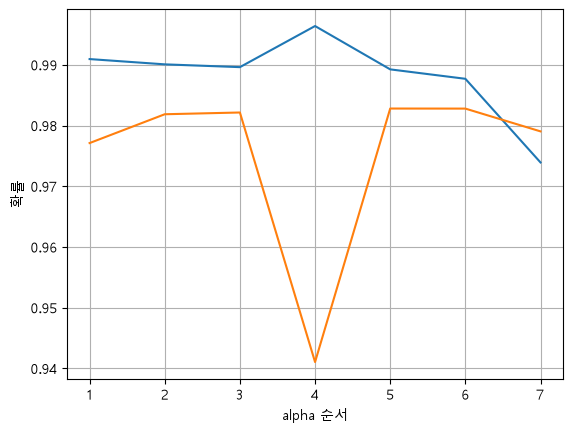

In [57]:
plt.plot(no_list,train_score)
plt.plot(no_list,test_score)
plt.xlabel('alpha 순서')
plt.grid()
plt.ylabel('확률')
plt.show()

In [55]:
print("train정답률 : ",score)
print("test정답률 : ",score2)

train정답률 :  0.973919270155311
test정답률 :  0.9790383837232647


In [58]:
ridge = Ridge(10)
ridge.fit(train_scaled,train_label)
score = ridge.score(train_scaled,train_label)
score2 = ridge.score(test_scaled,test_label)
print("train정답률 : ",score)
print("test정답률 : ",score2)

train정답률 :  0.9876984476491448
test정답률 :  0.9827901012337936


In [ ]:
# lr = LinearRegression()
# lr.fit(train_poly,train_label)
# predict = lr.predict(test_poly)
# print("예측결과 : ",predict)
# score = lr.score(train_poly,train_label)
# score2 = lr.score(test_poly,test_label)
# print("train정답률 : ",score)
# print("test정답률 : ",score2)

예측결과 :  [-12.05786108  36.31325908 252.49060349  97.11821645 132.45298338
 822.2632107  391.29566628 190.38630255 647.4853414  126.33310062
 936.44829     38.02751045 235.95552502 236.09503395]
train정답률 :  0.9963872340980052
test정답률 :  0.9410534492202449
